In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.metrics import mean_absolute_error

In [128]:
# Set Matplotlib defaults
plt.style.use("seaborn-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

/tmp/ipykernel_2493800/1950355325.py:2: MatplotlibDeprecationWarning: The seaborn styles shipped by Matplotlib are deprecated since 3.6, as they no longer correspond to the styles shipped by seaborn. However, they will remain available as 'seaborn-v0_8-<style>'. Alternatively, directly use the seaborn API instead.
  plt.style.use("seaborn-white")


# Here we focus on getting Fe from no abundance

In [129]:
sample_10k = pd.read_csv('sample_10k_restricted_columns.csv')

columns_for_Fe = ['FeH', 'RV',   'U_lsr', 'V_lsr', 'W_lsr', 'UW_lsr', 'UVW_lsr', 'P_gal']
#columns_for_Fe = ['G_lon', 'G_lat',  'RV', 'FeH', 'U_lsr', 'V_lsr', 'W_lsr', 'UW_lsr', 'UVW_lsr', 'P_gal']


sample_10k_Fe = sample_10k[columns_for_Fe]
sample_10k_Fe.head(5)

,FeH,RV,U_lsr,V_lsr,W_lsr,UW_lsr,UVW_lsr,P_gal
0,0.083736,26.048073,39.891391,7.389838,4.102849,40.101826,40.519500,98.8
1,-0.162360,13.875863,2.595274,-5.465397,9.672896,10.015007,5.189713,99.0
2,-0.712590,30.415070,17.200275,-40.405005,5.946438,18.199165,43.981363,97.3
3,0.009782,17.903835,6.965641,-5.564924,2.383295,7.362082,9.048305,99.2
4,-0.374150,14.412615,73.752895,-19.233505,104.578232,127.969121,76.902506,0.0


In [130]:
sample_10k_Fe_orig = sample_10k_Fe.copy()
y_apogee = sample_10k_Fe_orig['FeH']
X_apogee = sample_10k_Fe_orig.drop(columns = ['FeH'])

harps_sample = pd.read_csv('harps_sample.csv')
y_harps = harps_sample.FeH
X_harps = harps_sample[columns_for_Fe].drop(columns = ['FeH'])

galah_sample = pd.read_csv('galah_sample.csv')
y_galah = galah_sample.FeH
X_galah = galah_sample[columns_for_Fe].drop(columns = ['FeH'])


X_all = pd.concat([X_apogee, X_harps, X_galah], axis = 0)
y_all = pd.concat([y_apogee, y_harps, y_galah], axis = 0)

In [131]:
def fit_trasform(X):
    epsilon = 1e-6
    #log features
    X['Log_RV'] = np.log(X['RV'] + np.abs(X['RV'].min()))
    X['Log_U_lsr'] = np.log(X['U_lsr'] + np.abs(X['U_lsr'].min()) + epsilon)
    X['Log_V_lsr'] = np.log(X['V_lsr'] + np.abs(X['V_lsr'].min()) + epsilon)
    X['Log_W_lsr'] = np.log(X['W_lsr'] + np.abs(X['W_lsr'].min()) + epsilon)
    X['Log_UW_lsr'] = np.log(X['UW_lsr'])
    X['Log_UVW_lsr'] = np.log(X['UVW_lsr'])

    X['VW'] = np.sqrt(X['V_lsr']**2 + X['W_lsr']**2)


    return X

In [132]:
X_apogee = fit_trasform(X_apogee)

In [133]:
def best_fixed_feh(y):
    mae_min = 1
    for i in range(20):
        feh_value = -0.3 + i*0.01
        y_fixed = np.full(len(y), feh_value)
        mae_fixed = mean_absolute_error(y, y_fixed)
        if mae_fixed < mae_min:
            mae_min = mae_fixed
            best_feh = feh_value
    print (f'[Fe/H] = {best_feh:.2f} dex gives minimum value MAE = {mae_min:.2f}')

best_fixed_feh(y_apogee)

[Fe/H] = -0.23 dex gives minimum value MAE = 0.23


In [134]:
XGBR_best_params = {'max_depth': 8,
 'learning_rate': 0.01650932396680898,
 'n_estimators': 718,
 'min_child_weight': 17,
 'gamma': 0.8734730656391256,
 'subsample': 0.9177430986395497,
 'reg_alpha': 1.9993517532422743e-05,
 'reg_lambda': 0.0027365003586796235,
 'random_state': 0}

In [135]:
def model_test_CV(X, y, k=5):
    kf = KFold(n_splits=k, shuffle=True, random_state=40)
    mae_scores = []

    for train_index, test_index in kf.split(X, y):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y[train_index], y[test_index]
        

        mdl = XGBRegressor(**XGBR_best_params)
        mdl.fit(X_train, y_train)

        y_pred = mdl.predict(X_test)
        mae_score = mean_absolute_error(y_test, y_pred)

        mae_scores.append(mae_score)

    mean_mae = np.mean(mae_scores)
    std_mae = np.std(mae_scores)
    
    return mean_mae

mean_mae = model_test_CV(X_apogee, y_apogee, k=5)
print (f'MAE for XGB: {mean_mae:.3}')

MAE for XGB: 0.212


In [136]:
def testing_features(X, y):

    X_dropped = X.copy()

    for col in X.columns:
        X_dropped = X[col].drop(columns = [col])
        
        mean_mae = model_test_CV(X_dropped, y)
        print (f' Dropping {col} results to {mean_mae:.3}')

testing_features(X_apogee, y_apogee)

 Dropping RV results to 0.223
 Dropping U_lsr results to 0.227
 Dropping V_lsr results to 0.223
 Dropping W_lsr results to 0.218
 Dropping UW_lsr results to 0.225
 Dropping UVW_lsr results to 0.225
 Dropping P_gal results to 0.221
 Dropping Log_RV results to 0.223
 Dropping Log_U_lsr results to 0.227
 Dropping Log_V_lsr results to 0.223
 Dropping Log_W_lsr results to 0.218
 Dropping Log_UW_lsr results to 0.225
 Dropping Log_UVW_lsr results to 0.225
 Dropping VW results to 0.221


First 14 of 14 features:
VW             0.075157
V_lsr          0.062293
P_gal          0.062195
Log_V_lsr      0.058023
UVW_lsr        0.057418
Log_W_lsr      0.056571
W_lsr          0.051312
Log_UVW_lsr    0.051047
Log_RV         0.026057
Log_UW_lsr     0.023979
UW_lsr         0.023701
RV             0.021112
Log_U_lsr      0.013254
U_lsr          0.008190
Name: MI Scores, dtype: float64


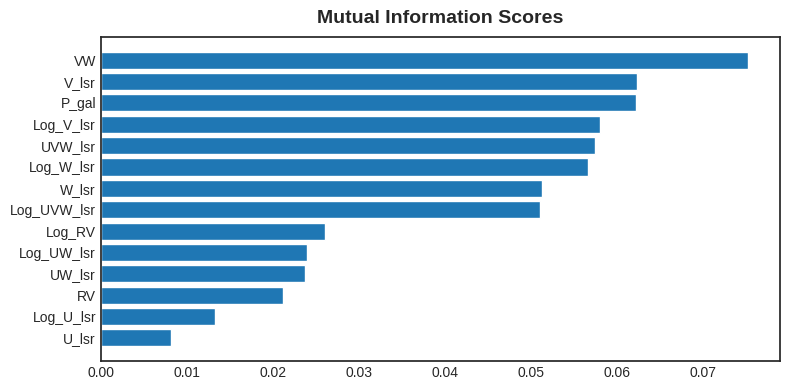

In [137]:
mi_scores = make_mi_scores(X_apogee, y_apogee,  plot = True)

In [138]:
X_scaled, X_test_scaled = preprocess_data(X_apogee, X_test=None, standardize=True, factorize=False)

random_state = 10

rfr = RandomForestRegressor(random_state = random_state)
xgbr = XGBRegressor(random_state = random_state)
lr = LinearRegression()
svr = SVR()
lgbr = LGBMRegressor(random_state = random_state)
catr = CatBoostRegressor(random_state=random_state, verbose=False)
voting_r = VotingRegressor(estimators=[('xgbr', xgbr), ('rfr', rfr),  ('svr', svr), ('lgbr', lgbr), ('catr', catr)])

#model_names = { 'xgbr': xgbr, 'rfr': rfr,  'svr': svr, 'lgbr': lgbr, 'catr': catr, 'voting_r': voting_r}
model_names = { 'xgbr': xgbr,  'svr': svr,  'catr': catr}

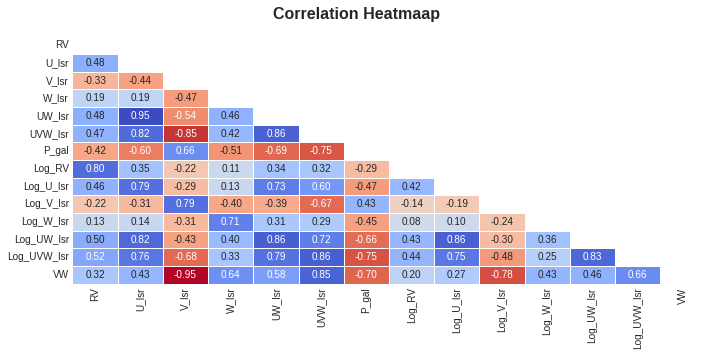

In [139]:
# Displays the correlation hitmap
corr_heatmap_plot(X_scaled)

In [140]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_new = X_apogee.copy()
#X_new.drop(columns = ['UW_lsr', 'UVW_lsr'], inplace = True)
# Calculate VIF for each predictor variable
vif = pd.DataFrame()
vif['Variable'] = X_new.columns
vif['VIF'] = [variance_inflation_factor(X_new.values, i) for i in range(X_new.shape[1])]

print(vif[vif['VIF'] > 0])

       Variable         VIF
0            RV    8.274188
1         U_lsr  251.943065
2         V_lsr   29.785572
3         W_lsr   29.543630
4        UW_lsr  349.578708
5       UVW_lsr  176.624456
6         P_gal    9.654637
7        Log_RV   30.191880
8     Log_U_lsr  104.846327
9     Log_V_lsr  146.016487
10    Log_W_lsr   17.359627
11   Log_UW_lsr  327.015044
12  Log_UVW_lsr  262.483925
13           VW   85.801508


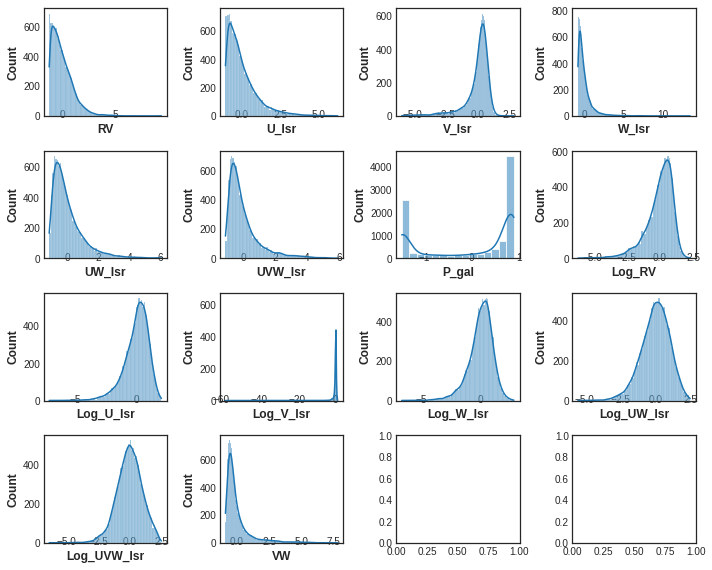

In [141]:
def plot_feature_distribution(df1, features):
    fig, ax = plt.subplots(4, 4, figsize=(10, 8))

    for i, feature in enumerate(features, start=1):
        plt.subplot(4,4, i)
        sns.histplot(df1[feature], kde=True)  # Using histplot for a histogram with a kernel density estimate
        plt.xlabel(feature, fontsize=12)
        plt.tick_params(axis='x', which='major', labelsize=10, pad=-6)
        plt.tick_params(axis='y', which='major', labelsize=10)

    plt.tight_layout()  # Adjust layout to prevent overlap
    plt.show()


plot_feature_distribution(X_scaled,  X_scaled.columns)

In [142]:
def individual_feature_importance(model, model_name, X, y, X_test, y_test):
    import matplotlib.pyplot as plt
    import numpy as np
    from sklearn.metrics import mean_absolute_error


    model_orig = model
    model.fit(X,y)

    feature_names = X.columns


    # Calculate MAE for the full set of features
    y_pred_full = model.predict(X_test)
    mae_full = mean_absolute_error(y_test, y_pred_full)

    # Calculate MAE for each subset of top features
    mae_top_features = []

    for i in range(1, len(feature_names)+1):
        top_features_subset = feature_names[i-1]
        model_subset = model_orig
        model_subset.fit(X[top_features_subset].values.reshape(-1,1), y)
        y_pred_subset = model_subset.predict(X_test[top_features_subset].values.reshape(-1,1))
        mae_top_subset = mean_absolute_error(y_test, y_pred_subset)
        mae_top_features.append(mae_top_subset)

    # Plotting
    plt.figure(figsize=(10, 6))

    # Plot the full set of features
    plt.bar(0, mae_full, color='gray', label='Full Features')

    # Plot the subset of top features
    plt.bar(range(1, len(feature_names)+1), mae_top_features, color='blue', label='Top Features')

    plt.axhline(y=0.23, color='red', linestyle='--', label='Threshold')


    plt.xlabel('Number of Top Features')
    plt.ylabel('Mean Absolute Error (MAE)')
    plt.xticks(range(len(feature_names) + 1), ['Full'] + list(feature_names), rotation=45, ha='right')

    plt.title(f'Feature Importance for {model_name}')
    plt.legend()
    plt.show()


model = XGBRegressor(**XGBR_best_params)
X_trian, X_test, y_train, y_test = train_test_split(X_apogee, y_apogee, test_size=0.2, random_state=42)
individual_feature_importance(model, 'XGBRegressor', X_trian, y_train, X_test, y_test)

Feature importance: ['W_lsr' 'RV' 'V_lsr' 'P_gal' 'U_lsr' 'UW_lsr' 'UVW_lsr' 'Log_UVW_lsr'
 'Log_UW_lsr' 'Log_W_lsr' 'Log_V_lsr' 'Log_U_lsr' 'Log_RV']


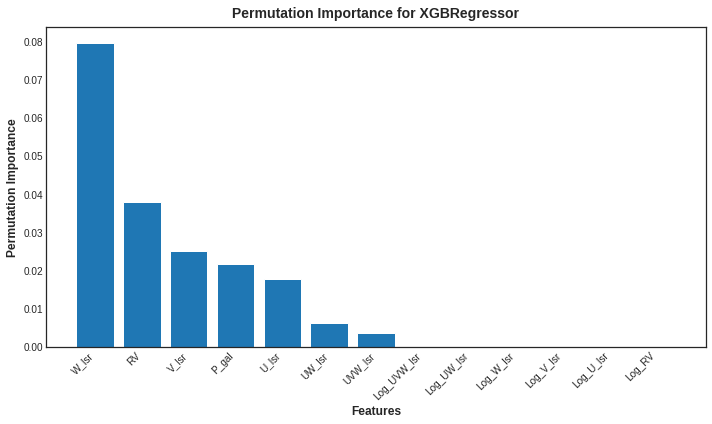

In [ ]:
def feat_importance_permut(model, model_name, X, y, n_repeats = 10):
    from sklearn.inspection import permutation_importance

    X_trian, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    model.fit(X_trian, y_train)
    

    # Calculate MAE on the original test set
    y_pred = model.predict(X_test)
    mae_original = mean_absolute_error(y_test, y_pred)

    # Use permutation importance to obtain feature importances
    result = permutation_importance(model, X_test, y_test, n_repeats=n_repeats, random_state=42)

    # Get feature importances and indices
    feature_importances = result.importances_mean
    sorted_indices = feature_importances.argsort()[::-1]

    print (f'Feature importance: {X.columns[sorted_indices].values}')

    # Plot the feature importances
    plt.figure(figsize=(10, 6))
    plt.bar(range(len(sorted_indices)), feature_importances[sorted_indices], tick_label=X.columns[sorted_indices])
    plt.xlabel('Features')
    plt.ylabel('Permutation Importance')
    plt.title(f'Permutation Importance for {model_name}')
    plt.xticks(rotation=45, ha='right')
    plt.show()

feat_importance_permut(model, 'XGBRegressor', X_apogee, y_apogee, n_repeats = 10)

In [ ]:
def ols(x, y):
    x_with_const = sm.add_constant(x)
    model = sm.OLS(y, x_with_const)
    results = model.fit()
    coeff1_ols, coeff2_ols = results.params[0], results.params[1]
    p_values = results.pvalues
    return coeff1_ols, coeff2_ols, p_values

MAE = 0.21


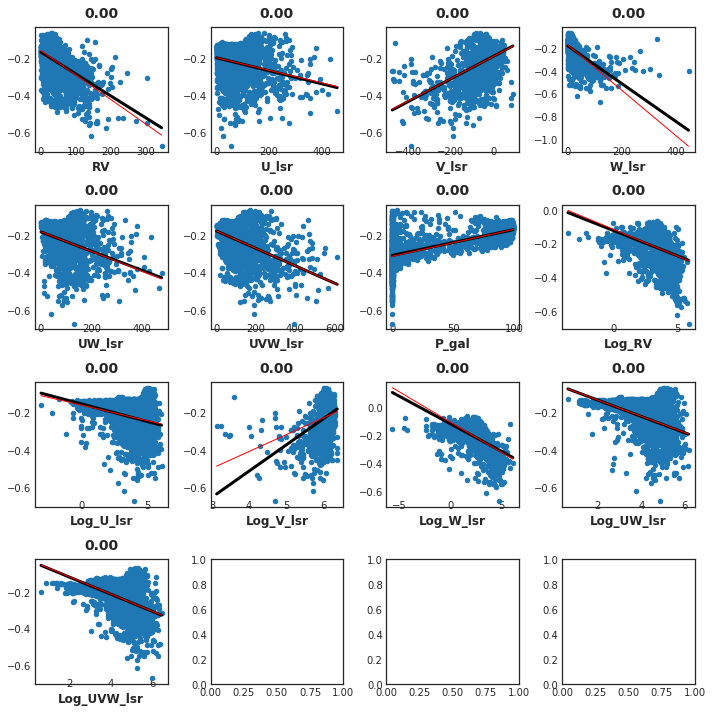

In [ ]:
def dependence_on_feature_plot(model, X, y, X_test, y_test):
    model.fit(X, y)
    y_pred = model.predict(X_test)
    print (f'MAE = {mean_absolute_error(y_test, y_pred):.2f}')

    sns.set_style('white')
    fig, ax = plt.subplots(4, 4, figsize=(10, 10))

    for i, feature in enumerate(X.columns, start=1):

        coeff1_ols, coeff2_ols, p_value = ols(X_test[feature], y_pred)
        coeff1_train_ols, coeff2_train_ols, p_value_train = ols(X[feature], y)

        x_line = np.array(np.arange(np.min(X_test[feature]), np.max(X_test[feature]),0.001))
        y_line = coeff1_ols +  coeff2_ols *x_line
        y_line_train = coeff1_train_ols +  coeff2_train_ols *x_line

        plt.subplot(4, 4, i)
        plt.scatter(X_test[feature], y_pred, s = 20)
        plt.plot(x_line, y_line, color = 'black', lw = 3)
        plt.plot(x_line, y_line_train, color = 'red', lw = 1, label = 'Train')
        plt.xlabel(feature, fontsize=12)
        plt.title(f'{p_value[1]:.2f}')
        plt.tick_params(axis='x', which='major', labelsize=10, pad=-6)
        plt.tick_params(axis='y', which='major', labelsize=10)


model = XGBRegressor(**XGBR_best_params)
X_trian, X_test, y_train, y_test = train_test_split(X_apogee, y_apogee, test_size=0.2, random_state=42)
dependence_on_feature_plot(model, X_trian, y_train, X_test, y_test)